In [14]:
pip install numpy matplotlib


Note: you may need to restart the kernel to use updated packages.


created cuboid shape is =(5, 10, 15)
we have finished simulation


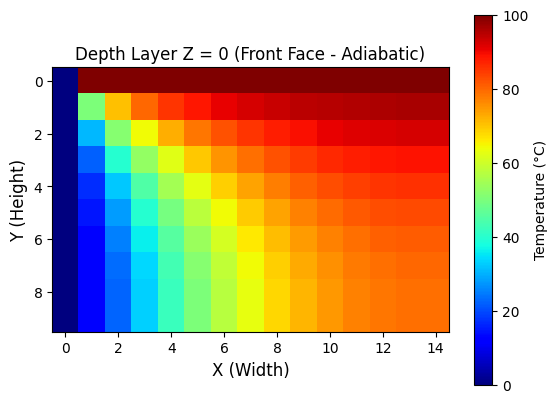

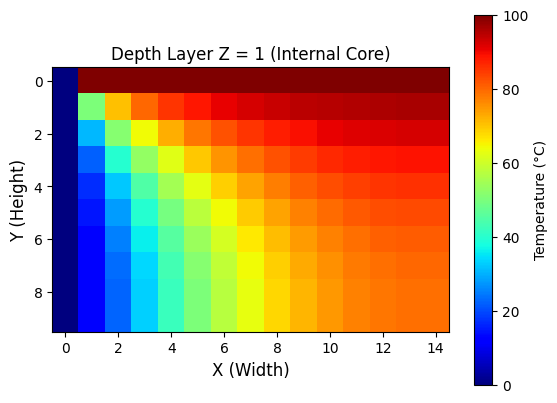

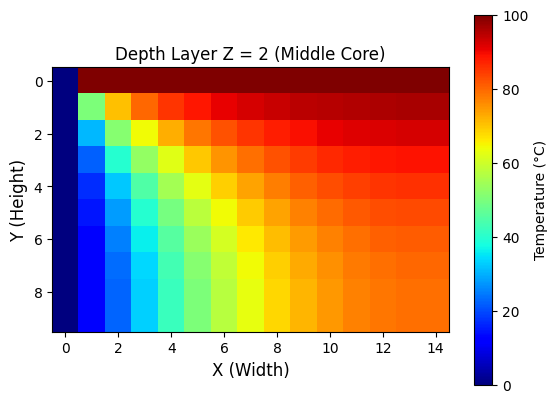

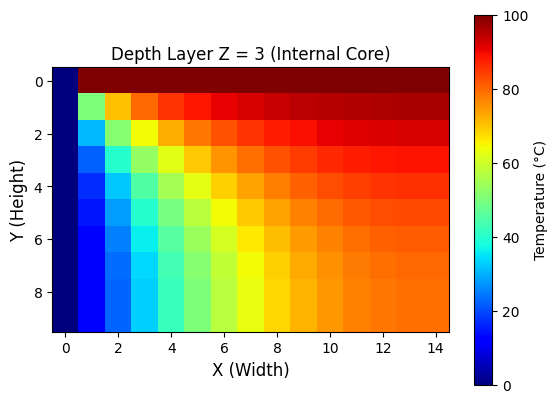

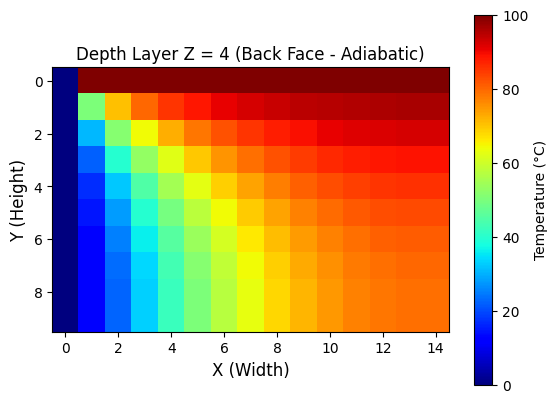

In [ ]:
import numpy as np
from pylab import *
#cuboid dimensions(z-depth,y-height,x-width)
nz = 5
ny = 10
nx = 15
#taking cuboid at room temp(20 degrees)
T = np.ones((nz,ny,nx))*20.0
print(f"created cuboid shape is ={T.shape}")
#set boundary conditions
#we are considering top wall is at 100 degrees(y = 0)
#and the left side wall is at 0 degrees(x = 0)
T[:,0,:] = 100.0
T[:,:,0] = 0.0
#here we have updated left face as for 0 degrees and for upper face 100 degrees(ONLY TWO)-but we should
#take remaing FOUR as also booundaries
#we are going to give the formula like AVERAGE OF ALL 6 SOURROUNDING BLOCKS


#we taking body is ADIABATIC
time_steps = 3000
T_new = T.copy()
for t in range(time_steps):
    for z in range(1,nz-1):
        for y in range(1,ny-1):
            for x in range(1,nx-1):
                T_new[z,y,x]=(T[z,y,x+1]+T[z,y,x-1]+T[z,y+1,x]+T[z,y-1,x]+T[z+1,y,x]+T[z-1,y,x])/6
#for ADIABATIC condition
    T_new[:,:,nx-1] = T_new[:,:,nx-2]
    T_new[:,ny-1,:] = T_new[:,ny-2,:]
    T_new[0, :, :]    = T_new[1, :, :] 
    T_new[nz-1,:,:] = T_new[nz-2,:,:]

    #make the fixed boundaries stay constant( bcz above you have given colon so you are changing everything)
    T_new[:,0,:] = 100.0
    T_new[:,:,0] = 0.0

    T = T_new.copy()
print("we have finished simulation")
#DATA PLOTTING
#5 separate figures, one for each Z-depth layer

figure(1)
title('Depth Layer Z = 0 (Front Face - Adiabatic)')
imshow(T[0, :, :], cmap='jet', vmin=0, vmax=100)
xlabel('X (Width)', fontsize=12)
ylabel('Y (Height)', fontsize=12)
colorbar(label='Temperature (°C)')

plt.savefig("thermal_slice_contour_z0.png", dpi=300, bbox_inches="tight")

figure(2)
title('Depth Layer Z = 1 (Internal Core)')
imshow(T[1, :, :], cmap='jet', vmin=0, vmax=100)
xlabel('X (Width)', fontsize=12)
ylabel('Y (Height)', fontsize=12)
colorbar(label='Temperature (°C)')

plt.savefig("thermal_slice_contour_z1.png", dpi=300, bbox_inches="tight")

figure(3)
title('Depth Layer Z = 2 (Middle Core)')
imshow(T[2, :, :], cmap='jet', vmin=0, vmax=100)
xlabel('X (Width)', fontsize=12)
ylabel('Y (Height)', fontsize=12)
colorbar(label='Temperature (°C)')

plt.savefig("thermal_slice_contour_z2.png", dpi=300, bbox_inches="tight")

figure(4)
title('Depth Layer Z = 3 (Internal Core)')
imshow(T[3, :, :], cmap='jet', vmin=0, vmax=100)
xlabel('X (Width)', fontsize=12)
ylabel('Y (Height)', fontsize=12)
colorbar(label='Temperature (°C)')

plt.savefig("thermal_slice_contour_z3.png", dpi=300, bbox_inches="tight")

figure(5)
title('Depth Layer Z = 4 (Back Face - Adiabatic)')
imshow(T[4, :, :], cmap='jet', vmin=0, vmax=100)
xlabel('X (Width)', fontsize=12)
ylabel('Y (Height)', fontsize=12)
colorbar(label='Temperature (°C)')

plt.savefig("thermal_slice_contour_z4.png", dpi=300, bbox_inches="tight")

plt.show()

